In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
display(df.head(10).T)

,0,1,2,3,4,5,6,7,8,9
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU,9305-CDSKC,1452-KIOVK,6713-OKOMC,7892-POOKP,6388-TABGU
gender,Female,Male,Male,Male,Female,Female,Male,Female,Female,Male
SeniorCitizen,0,0,0,0,0,0,0,0,0,0
Partner,Yes,No,No,No,No,No,No,No,Yes,No
Dependents,No,No,No,No,No,No,Yes,No,No,Yes
tenure,1,34,2,45,2,8,22,10,28,62
PhoneService,No,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Yes
MultipleLines,No phone service,No,No,No phone service,No,Yes,Yes,No phone service,Yes,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic,Fiber optic,Fiber optic,DSL,Fiber optic,DSL
OnlineSecurity,No,Yes,Yes,Yes,No,No,No,Yes,No,Yes


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [12]:
df['TotalCharges'] = df['TotalCharges'].astype(str).str.strip()
df['TotalCharges'] = df['TotalCharges'].replace('',None)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(),errors='coerce')

In [13]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [14]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [15]:
df.dropna(inplace=True)

In [16]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


# Data Visualization

<Axes: >

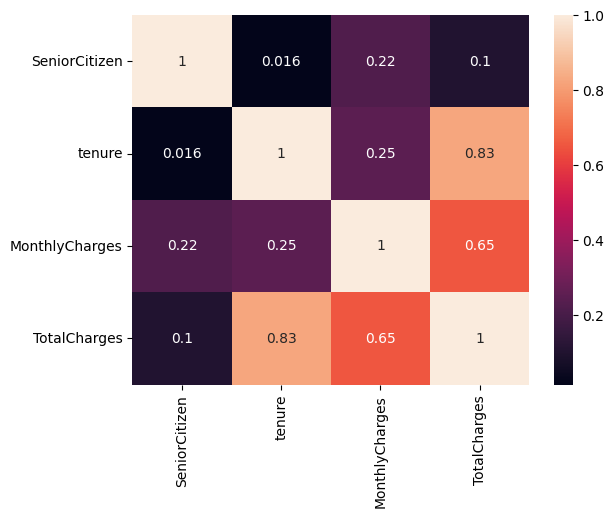

In [17]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='Churn', ylabel='count'>

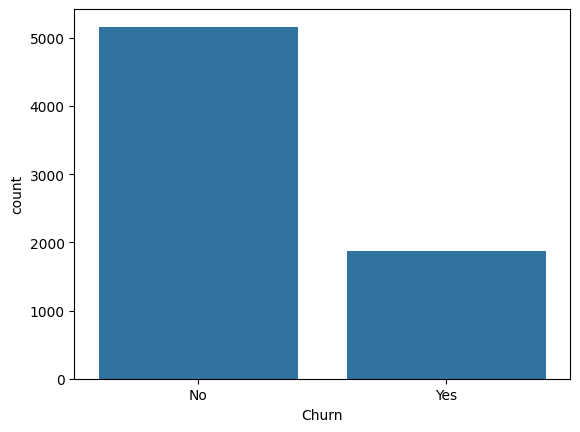

In [18]:
sns.countplot(x='Churn',data=df)

In [19]:
df['Churn'].value_counts()

,count
Churn,
No,5163
Yes,1869


<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

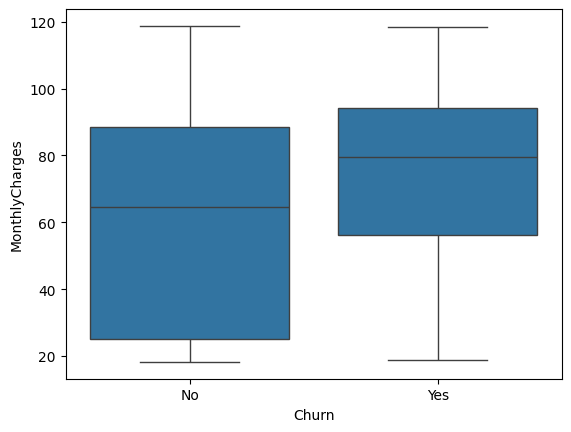

In [20]:
sns.boxplot(x='Churn',y='MonthlyCharges',data=df)

<Axes: xlabel='Churn', ylabel='TotalCharges'>

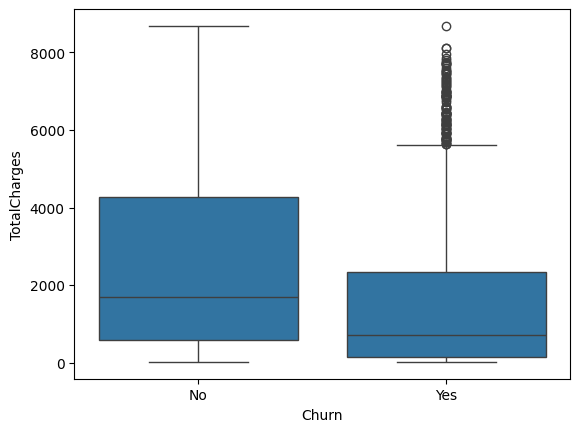

In [21]:
sns.boxplot(x='Churn',y='TotalCharges',data=df)

In [22]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

<Axes: xlabel='tenure', ylabel='Count'>

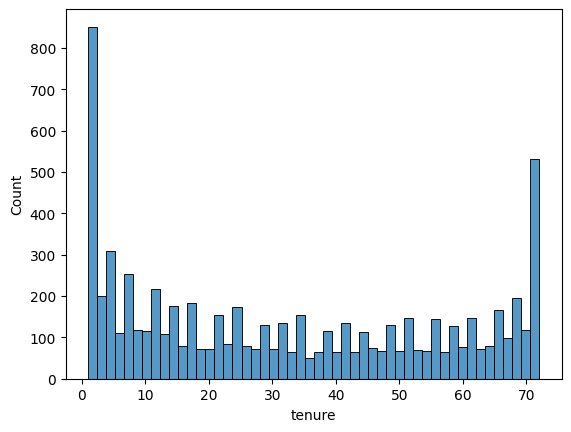

In [23]:
sns.histplot(data=df,x='tenure',bins=50)

<Axes: xlabel='MonthlyCharges', ylabel='Count'>

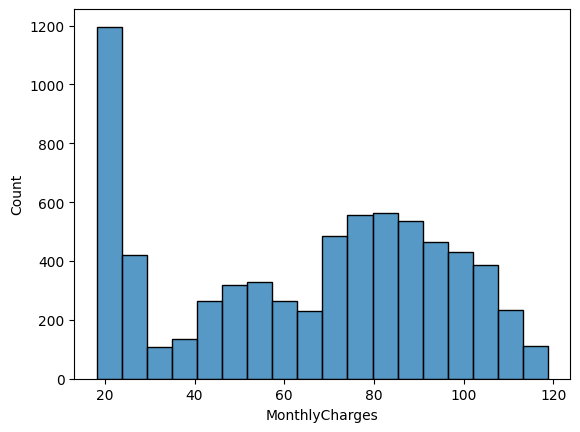

In [24]:
sns.histplot(x='MonthlyCharges',data=df)

<Axes: xlabel='TotalCharges', ylabel='Count'>

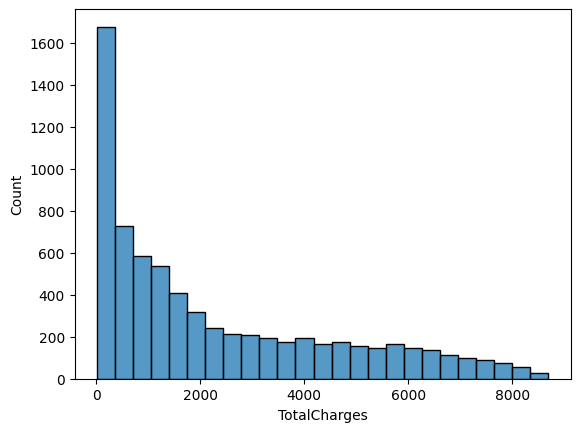

In [25]:
sns.histplot(x='TotalCharges',data=df)

In [26]:
df['TotalCharges'].skew()

np.float64(0.9616424997242504)

In [27]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [28]:
df['PaymentMethod'].unique()

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

In [29]:
#Outliers
num_features = df.select_dtypes(include='number') #int64 or float 64
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((num_features < lower_bound) | (num_features > upper_bound))
print(outliers.sum())

SeniorCitizen     1142
tenure               0
MonthlyCharges       0
TotalCharges         0
dtype: int64


In [30]:
df['SeniorCitizen'].max()

1

<Axes: xlabel='tenure', ylabel='TotalCharges'>

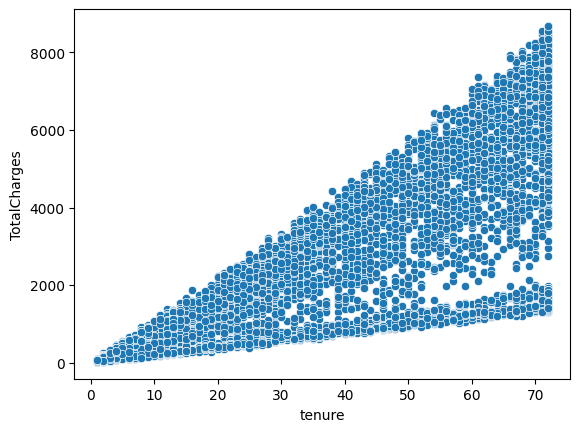

In [31]:
sns.scatterplot(x='tenure',y='TotalCharges',data=df)

In [32]:
categorial_col = ['gender','Partner', 'Dependents','PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']
log_col = ['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']

feature_col = categorial_col + log_col


# Train Test Split Data

In [33]:
from sklearn.model_selection import train_test_split

x = df[feature_col]
y = df['Churn']

y = df['Churn'].map({'No': 0, 'Yes': 1})

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)


# Pipeline

In [34]:
from numpy.random import standard_cauchy
from sklearn import pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

# Categorical Features
categorical_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore')),
])

# Numeric Features
log_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scaler',StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('categorical_col',categorical_pipeline,categorial_col),
    ('log_col',log_pipeline,log_col)
])


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

lr_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('logisticreggressor',LogisticRegression(class_weight={0:1, 1:2}, C=0.5, max_iter=1000))
])

lr_pipeline.fit(x_train,y_train)
y_pred = lr_pipeline.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test,y_pred)}')
print(f'Precision Score: {precision_score(y_test,y_pred)}')
print(f'Recall_Score: {recall_score(y_test,y_pred)}')

from sklearn.metrics import precision_recall_curve
proba = lr_pipeline.predict_proba(x_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
# 0.80 recall ke qareeb sabse high precision wala threshold dhoondo
import numpy as np
idx = np.where(rec[:-1] >= 0.80)[0][-1]
best_thr = thr[idx]
y_pred = (proba >= best_thr).astype(int)

Accuracy: 0.7619047619047619
Precision Score: 0.5377176015473888
Recall_Score: 0.7433155080213903


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('randomforestclassifier',RandomForestClassifier(random_state = 42))
])

rf_pipeline.fit(x_train,y_train)
y_pred = rf_pipeline.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test,y_pred)}')
print(f'Precision Score: {precision_score(y_test,y_pred)}')
print(f'Recall_Score: {recall_score(y_test,y_pred)}')


Accuracy: 0.7896233120113717
Precision Score: 0.6335616438356164
Recall_Score: 0.4946524064171123


In [37]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('decisiontreeclassifier',DecisionTreeClassifier(random_state = 42))
])

dt_pipeline.fit(x_train,y_train)
y_pred = dt_pipeline.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test,y_pred)}')
print(f'Precision Score: {precision_score(y_test,y_pred)}')
print(f'Recall_Score: {recall_score(y_test,y_pred)}')

Accuracy: 0.7185501066098081
Precision Score: 0.4719387755102041
Recall_Score: 0.4946524064171123


In [38]:
print("y_train unique values:", y_train.unique())
print("y_train dtype:", y_train.dtype)
print("y_test unique values:", y_test.unique())

y_train unique values: [0 1]
y_train dtype: int64
y_test unique values: [0 1]


In [39]:
from catboost import CatBoostClassifier

cbc_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('decisiontreeclassifier',CatBoostClassifier(random_state = 42))
])

cbc_pipeline.fit(x_train,y_train)
y_pred = cbc_pipeline.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test,y_pred)}')
print(f'Precision Score: {precision_score(y_test,y_pred)}')
print(f'Recall_Score: {recall_score(y_test,y_pred)}')



Learning rate set to 0.02154
0:	learn: 0.6785159	total: 68.3ms	remaining: 1m 8s
1:	learn: 0.6638547	total: 94.2ms	remaining: 47s
2:	learn: 0.6496826	total: 111ms	remaining: 36.8s
3:	learn: 0.6378315	total: 126ms	remaining: 31.3s
4:	learn: 0.6254880	total: 139ms	remaining: 27.7s
5:	learn: 0.6139233	total: 155ms	remaining: 25.6s
6:	learn: 0.6034640	total: 169ms	remaining: 24s
7:	learn: 0.5931291	total: 182ms	remaining: 22.6s
8:	learn: 0.5838373	total: 198ms	remaining: 21.8s
9:	learn: 0.5745956	total: 209ms	remaining: 20.7s
10:	learn: 0.5660139	total: 223ms	remaining: 20.1s
11:	learn: 0.5580370	total: 241ms	remaining: 19.8s
12:	learn: 0.5520358	total: 260ms	remaining: 19.7s
13:	learn: 0.5448595	total: 277ms	remaining: 19.5s
14:	learn: 0.5383278	total: 285ms	remaining: 18.7s
15:	learn: 0.5324628	total: 298ms	remaining: 18.3s
16:	learn: 0.5257323	total: 310ms	remaining: 17.9s
17:	learn: 0.5198131	total: 325ms	remaining: 17.8s
18:	learn: 0.5142796	total: 335ms	remaining: 17.3s
19:	learn: 0.5

In [40]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'randomforestclassifier__n_estimators': [100, 200, 300, 500],
    'randomforestclassifier__max_depth': [None, 5, 10, 20, 30],
    'randomforestclassifier__max_features': ['sqrt', 'log2', None],
    'randomforestclassifier__min_samples_split': [2, 5, 10],
    'randomforestclassifier__min_samples_leaf': [1, 2, 4],
    'randomforestclassifier__class_weight': [None, 'balanced']
    }

random_search = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = param_grid,
    cv = 5,
    n_jobs = -1,
    verbose = 2,
    scoring ='accuracy'
)

random_search.fit(x_train,y_train)
print(random_search.best_params_)
print(random_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
{'randomforestclassifier__n_estimators': 500, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__min_samples_leaf': 4, 'randomforestclassifier__max_features': 'log2', 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': None}
0.8030222222222223


In [41]:
e = random_search.best_estimator_
rf_best_pred = e.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test,rf_best_pred)}')
print(f'Precision Score: {precision_score(y_test, rf_best_pred)}')
print(f'Recall Score: {recall_score(y_test,rf_best_pred)}')

Accuracy: 0.7938877043354655
Precision Score: 0.6468531468531469
Recall Score: 0.4946524064171123


In [48]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'randomforestclassifier__n_estimators': [50, 75],
    'randomforestclassifier__max_depth': [None, 5, 10],
    'randomforestclassifier__min_samples_split': [2, 5],
    'randomforestclassifier__min_samples_leaf': [1, 2],
    }

grid_search = GridSearchCV(
    estimator = rf_pipeline,
    param_grid = param_grid,
    cv = 5,
    n_jobs = -1,
    verbose = 2,
    scoring ='accuracy'
)

grid_search.fit(x_train,y_train)
print(grid_search.best_params_)
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
{'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 2, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 50}
0.8019555555555555


In [50]:
rf_best_pipeline =grid_search.best_estimator_
rf_best_pred = rf_best_pipeline.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test,rf_best_pred)}')
print(f'Precision Score: {precision_score(y_test, rf_best_pred)}')
print(f'Recall Score: {recall_score(y_test,rf_best_pred)}')

Accuracy: 0.7938877043354655
Precision Score: 0.6381578947368421
Recall Score: 0.5187165775401069


In [51]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

y = df['Churn'].map({'No': 0, 'Yes': 1})

# 1) stratified split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

# 2) imbalance handle karo
lr = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', C=0.5, max_iter=1000))
])

# 3) CV predictions se threshold chuno (test set ko mat chhuo)
skf = StratifiedKFold(5, shuffle=True, random_state=42)
proba_cv = cross_val_predict(lr, x_train, y_train, cv=skf, method='predict_proba')[:, 1]

prec, rec, thr = precision_recall_curve(y_train, proba_cv)
ok = np.where(rec[:-1] >= 0.75)[0]               # target recall 75%
best_thr = thr[ok[np.argmax(prec[:-1][ok])]]     # us mein best precision
print('Threshold:', best_thr)

# 4) aakhir mein test par ek baar
lr.fit(x_train, y_train)
test_proba = lr.predict_proba(x_test)[:, 1]
y_pred = (test_proba >= best_thr).astype(int)
print(classification_report(y_test, y_pred))
print('ROC-AUC:', roc_auc_score(y_test, test_proba))

Threshold: 0.5544865587173821
              precision    recall  f1-score   support

           0       0.90      0.75      0.81      1033
           1       0.52      0.76      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.75      0.72      1407
weighted avg       0.80      0.75      0.76      1407

ROC-AUC: 0.8400005694436536


In [52]:
import joblib

model_bundle = {
    'pipeline': lr_pipeline,
    'feature_cols': feature_col,          # columns ka order
}

joblib.dump(model_bundle, 'churn_model.pkl')

['churn_model.pkl']

In [53]:
p = joblib.load('churn_model.pkl')
y_chk = (p['pipeline'].predict(x_test))
print(classification_report(y_test, y_chk))

              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1033
           1       0.54      0.74      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.76      0.77      1407

